In [1]:
import badgers
badgers.__version__

'0.0.15'

In [2]:
from badgers.generators.tabular_data.drift.causal import CausalDriftGenerator

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import pandas as pd

from badgers.core.dgp import OlsDGP

In [4]:
def generate_linear_data(graph, n_samples=100, rng=None, coefficients=None):
    """Generate data from a linear structural equation model on a DAG.

    Each edge (u -> v) carries a coefficient w. Every node value is
        v = sum_{u in parents(v)} w_{u,v} * u + noise
    with noise ~ N(0, 1).
    """
    if rng is None:
        rng = np.random.default_rng(42)
    if coefficients is None:
        coefficients = {edge: 1.0 for edge in graph.edges()}

    nodes = list(graph.nodes())
    node_to_idx = {node: i for i, node in enumerate(nodes)}
    X = np.zeros((n_samples, len(nodes)))
    for node in nx.topological_sort(graph):
        idx = node_to_idx[node]
        parents = list(graph.predecessors(node))
        if not parents:
            X[:, idx] = rng.normal(size=n_samples)
        else:
            X[:, idx] = rng.normal(size=n_samples)
            for parent in parents:
                coef = coefficients.get((parent, node), 1.0)
                X[:, idx] += coef * X[:, node_to_idx[parent]]
    return X, {node: i for i, node in enumerate(nodes)}


def draw_graph(graph, title=None):
    """Draw a DAG with node labels."""
    fig, ax = plt.subplots(1, figsize=(6, 2))
    pos = nx.spring_layout(graph, seed=42)
    nx.draw(graph, pos, ax=ax, node_color="lightblue", node_size=800, arrowsize=15)
    nx.draw_networkx_labels(graph, pos, ax=ax)
    if title:
        ax.set_title(title, fontsize=12)
    ax.axis("off")
    return fig


def plot_2panel(X, Xt, yt, x_idx=0, y_idx=1, x_name="X", y_name="Y"):
    """Original | Transformed scatter of two dimensions.

    The transformed panel is coloured by the generator's labels (which rows
    received the defect). Rows with NaN values are drawn as black 'x' markers.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
    sns.scatterplot(x=X[:, x_idx], y=X[:, y_idx], color="C0", ax=axes[0])
    sns.scatterplot(x=Xt[:, x_idx], y=Xt[:, y_idx], color="C1", ax=axes[1])
    axes[0].set_title("Original")
    axes[1].set_title("Transformed")
    axes[0].set_xlabel(x_name)
    axes[1].set_xlabel(x_name)
    axes[0].set_ylabel(y_name)
    axes[1].set_ylabel(y_name)
    plt.tight_layout()
    return fig

## 1. Building the causal graph

Unlike the classic Badgers generators, the causal generators take a **causal graph** (a directed acyclic graph, or DAG) as input. The graph plays two roles:

1. **It defines the data generating process.** We generate the data *from* the graph using a linear structural equation model, so the graph genuinely explains how the columns are related.
2. **It drives the defect.** When a node is perturbed, the effect **propagates to its descendants** along the directed edges and nowhere else.

For these tutorials we use a simple **chain** `X → Y → Z`:

- **X** is a root (exogenous) node.
- **Y** depends on X.
- **Z** depends on Y.

We represent the graph with `networkx.DiGraph` and provide an explicit `column_mapping` that tells the generator which column of the data each node lives in.


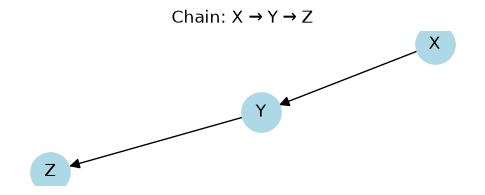

In [5]:
# --- Build the chain X -> Y -> Z ---
chain = nx.DiGraph()
chain.add_edges_from([("X", "Y"), ("Y", "Z")])

draw_graph(chain, title="Chain: X → Y → Z")
plt.show()


## 2. Generating data from the DAG

We draw 100 samples from the chain. Each node is a weighted sum of its parents plus Gaussian noise; the edge weights set the strength of each causal effect.


In [6]:
rng = np.random.default_rng(42)

X, column_mapping = generate_linear_data(
    chain, n_samples=100, rng=rng,
    coefficients={("X", "Y"): 2.0, ("Y", "Z"): 0.5},
)
print(f"X shape: {X.shape}")
print(f"column_mapping: {column_mapping}")


X shape: (100, 3)
column_mapping: {'X': 0, 'Y': 1, 'Z': 2}


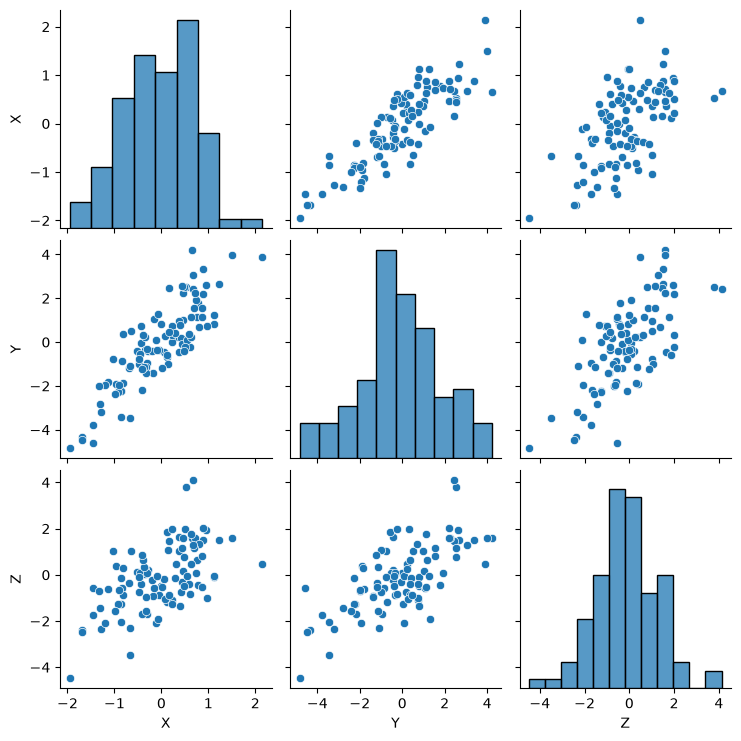

In [7]:
sns.pairplot(pd.DataFrame(X,columns=column_mapping.keys()))

## 3. Fitting the data generation process (DGP)

Causal generators take a **fitted world** — a `DGP` object — via the `dgp=` argument of the constructor (or `use_dgp()`). They have **no public `fit()`**: fitting lives entirely on the DGP.

Building the default world is one line: `OlsDGP(graph, column_mapping)` is a deterministic per-node least-squares backend that learns, for every node, the linear coefficients from its parents and the residual noise, fitted on the *original* data with `.fit(X)`.

Fitting is deterministic (pure NumPy) and needs no extras. Custom estimation backends implementing the `DGP` protocol can be built the same way (the optional extras `pip install "badgers[pymc]"` and `pip install "badgers[dowhy]"` install PyMC + PyTensor and DoWhy for the corresponding backends).

In [8]:
dgp = OlsDGP(chain, column_mapping).fit(X.copy())

gen = CausalDriftGenerator(random_generator=np.random.default_rng(0), dgp=dgp)

## 4. Generate causally-propagated drift

The `CausalDriftGenerator` applies a **systematic shift** (drawn once, then applied to every affected row) to a perturbation node and propagates it to descendants. Unlike noise, the shift is *constant* — the whole node (and its downstream effect) moves together.

`drift_std` is expressed in units of the column's standard deviation.


In [13]:
Xt, yt = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    drift_std=5.0,
)
print(f"output shape: {Xt.shape}")


output shape: (100, 3)


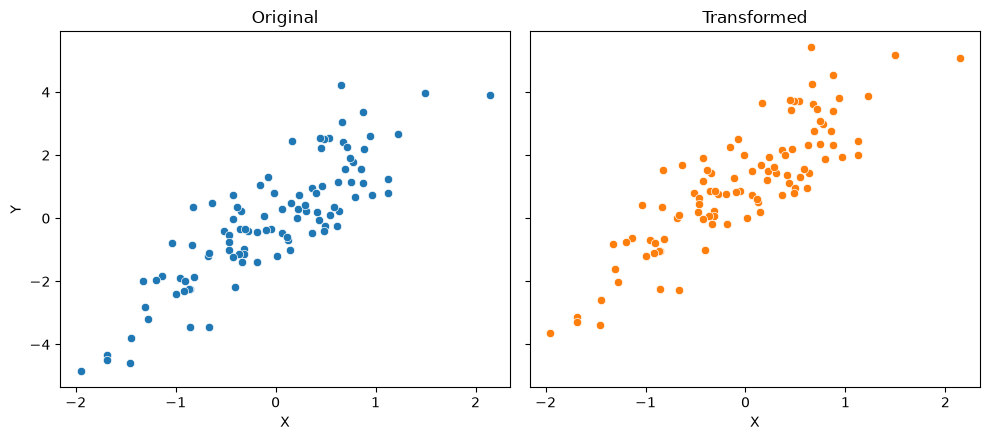

In [10]:
_ = plot_2panel(X, Xt, yt, x_idx=0, y_idx=1, x_name='X', y_name='Y')

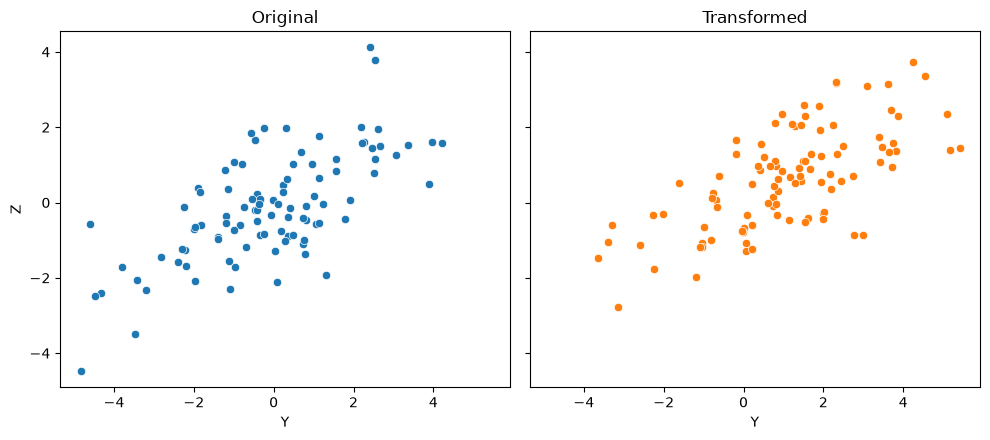

In [11]:
_ = plot_2panel(X, Xt, yt, x_idx=1, y_idx=2, x_name='Y', y_name='Z')

### Propagation to the descendant (Y → Z)

The drift is a single systematic shift, but the propagation is **Pearl surgery with fresh noise**: Z is not translated by a rigid delta — it is **recomputed** from its (shifted) parent through the fitted structural equation, `Z_new = f(Y_shifted) + fresh_noise`. The systematic part of the shift carries through (Z moves because Y moved), but Z's scatter is **re-rolled**, not preserved: the descendant cloud keeps roughly its original width while its position follows the parent's shift. This is what distinguishes drift from noise: drift shifts a node *systematically* (one draw applied to all affected rows), noise scatters it row-by-row — and in both cases the descendants' noise is freshly drawn, never inherited.

## Summary

1. Drift is a *single* systematic shift, drawn once and applied to all affected rows.
2. It propagates to descendants via **Pearl surgery with fresh noise** (`dgp.intervene`): descendants move with their parents, and their scatter is re-rolled through the fitted structural equations, not inherited.
3. In a scatter plot this shows up as a systematic shift of the affected cloud: its position moves as a whole, without the row-by-row scatter of the noise defect.